## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: August 10, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 10 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Neural Networks
 


## Summarize your results.

In [10]:
import tensorflow as tf
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras import layers, models
import ssl
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


## Load the MNIST data set.


In [11]:


# Disable SSL verification (insecure)
ssl._create_default_https_context = ssl._create_unverified_context

# Load MNIST
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

## Display the first five images in the training data set. Compare these to the first five training labels

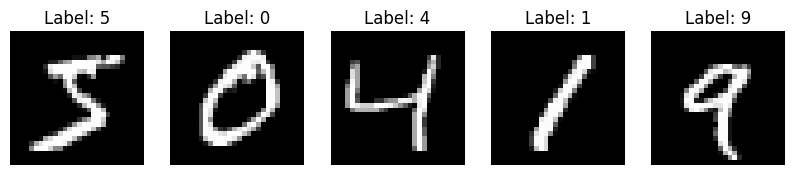

In [12]:
# Display first 5 images with labels
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

## Build and train a CNN classifier on the MNIST training set.


In [13]:
# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension (CNNs expect height, width, channels)
x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]

# Build CNN model
model = models.Sequential([
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0–9
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    x_train, y_train,
    batch_size=128,
    epochs=5,
    validation_split=0.1
)

# Evaluate on the test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

Epoch 1/5
422/422 [==============================] - 5s 12ms/step - loss: 0.2316 - accuracy: 0.9321 - val_loss: 0.0650 - val_accuracy: 0.9823
Epoch 2/5
422/422 [==============================] - 5s 13ms/step - loss: 0.0623 - accuracy: 0.9809 - val_loss: 0.0413 - val_accuracy: 0.9888
Epoch 3/5
422/422 [==============================] - 5s 12ms/step - loss: 0.0420 - accuracy: 0.9869 - val_loss: 0.0409 - val_accuracy: 0.9887
Epoch 4/5
422/422 [==============================] - 5s 12ms/step - loss: 0.0315 - accuracy: 0.9902 - val_loss: 0.0352 - val_accuracy: 0.9900
Epoch 5/5
422/422 [==============================] - 5s 12ms/step - loss: 0.0252 - accuracy: 0.9922 - val_loss: 0.0370 - val_accuracy: 0.9890
Test accuracy: 0.9884


## Display a confusion matrix on the test set classifications.


313/313 [==============================] - 1s 2ms/step


<Figure size 800x800 with 0 Axes>

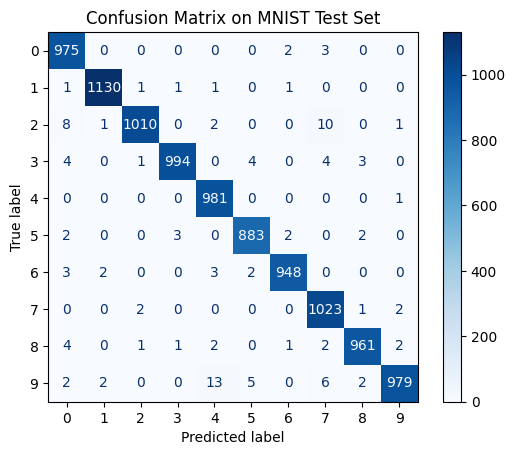

In [14]:
# Predict labels for test set
y_pred = model.predict(x_test)
y_pred_labels = np.argmax(y_pred, axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_labels)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
plt.figure(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix on MNIST Test Set")
plt.show()